# autoencoder_testing_v7  (NORMAL / UNKNOWN)

Run `autoencoder_training_v7.ipynb` first. Keep `autoencoder_v7_common.py` in this folder.

Labelled data is used here **only to report** how the saved model behaves. It never influences training, the threshold or the configuration. Output labels are **NORMAL** (reconstruction error at or below the benign threshold) and **UNKNOWN** (above it).

* *Benign flagged UNKNOWN* = false-alarm rate on normal traffic.
* *UNKNOWN rate* per attack family = share of that family the autoencoder does not accept as normal.

## 1. Imports and paths

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, average_precision_score

from autoencoder_v7_common import (
    VERSION,
    SPLIT_TAG,
    FEATURES,
    LABELS,
    validate_frame,
    transform,
    reconstruction_mse,
    classify
)

# --------------------------------------------------
# 1. Project paths
# --------------------------------------------------

PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "Data_V2"

TEST_FILE = DATA_DIR / "unknown_test_Bot_FTP_Slowhttptest.parquet"

FALLBACK_FILE = DATA_DIR / "known_test.parquet"

MODEL_DIR = (
    PROJECT_ROOT / "saved-models" / f"autoencoder_{VERSION}"
)

RESULTS_DIR = (
    PROJECT_ROOT / "outputs" / "results" / f"autoencoder_{VERSION}"
)

PREV_PREDICTIONS = (
    PROJECT_ROOT
    / "outputs"
    / "results"
    / "autoencoder_v6"
    / "autoencoder_v6_known_test_predictions.csv"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 2. Convert Parquet to CSV
# --------------------------------------------------

def convert(parquet_path):
    """
    Convert a Parquet file into CSV.
    Keep the original Parquet file unchanged.
    """

    csv_path = parquet_path.with_suffix(".csv")

    if csv_path.exists():
        print("CSV already exists:", csv_path.name)
        return csv_path

    if not parquet_path.exists():
        raise FileNotFoundError(
            f"Parquet file not found: {parquet_path}"
        )

    print("Converting:", parquet_path.name)

    df = pd.read_parquet(parquet_path)

    df.to_csv(
        csv_path,
        index=False
    )

    print("CSV saved:", csv_path.name)

    return csv_path


# --------------------------------------------------
# 3. Convert and load UNKNOWN and KNOWN test datasets
# --------------------------------------------------
UNKNOWN_FILE = DATA_DIR / "unknown_test_Bot_FTP_Slowhttptest.parquet"
KNOWN_FILE = DATA_DIR / "known_test.parquet"

def csv_file(parquet_path):
    csv_path = parquet_path.with_suffix(".csv")
    if not csv_path.exists():
        return convert(parquet_path)
    return csv_path

UNKNOWN_CSV = csv_file(UNKNOWN_FILE)
KNOWN_CSV = csv_file(KNOWN_FILE)

unknown_raw = pd.read_csv(UNKNOWN_CSV, low_memory=False)
known_raw = pd.read_csv(KNOWN_CSV, low_memory=False)
print("Unknown test:", UNKNOWN_CSV.name, unknown_raw.shape)
print("Known test:", KNOWN_CSV.name, known_raw.shape)


Unknown test: unknown_test_Bot_FTP_Slowhttptest.csv (13107, 71)
Known test: known_test.csv (375924, 71)


## 2. Load saved model; match all unknown attacks with equally many BENIGN flows from known_test.csv


In [2]:
selection = json.loads((MODEL_DIR / f'autoencoder_{VERSION}_selection.json').read_text())
models = [tf.keras.models.load_model(MODEL_DIR / f) for f in selection['model_files']]
prep = joblib.load(MODEL_DIR / f'autoencoder_{VERSION}_preprocessing.joblib')
if prep['features'] != FEATURES or models[0].input_shape[-1] != prep['input_dim']:
    raise ValueError('Training/test feature mismatch')

# Use ALL held-out UNKNOWN attack rows.
# Draw the SAME number of BENIGN rows from known_test.csv.
unknown_raw.columns = unknown_raw.columns.astype(str).str.strip()
known_raw.columns = known_raw.columns.astype(str).str.strip()
for name, frame in [("unknown_test", unknown_raw), ("known_test", known_raw)]:
    if "Label" not in frame.columns:
        raise KeyError(f"{name} must contain a Label column")
    frame["Label"] = frame["Label"].astype(str).str.strip()

attack_df = unknown_raw.loc[~unknown_raw["Label"].str.upper().eq("BENIGN")].copy()
benign_pool = known_raw.loc[known_raw["Label"].str.upper().eq("BENIGN")].copy()
if attack_df.empty:
    raise ValueError("No attacks found in unknown test CSV")
if len(benign_pool) < len(attack_df):
    raise ValueError(f"Not enough BENIGN records in known_test: need {len(attack_df)}, have {len(benign_pool)}")

benign_df = benign_pool.sample(n=len(attack_df), random_state=42, replace=False)
test_balanced = pd.concat([benign_df, attack_df], ignore_index=True)
test_balanced = test_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
test_df, X_test = validate_frame(test_balanced, "test_balanced")
labels = test_df["Label"].astype(str).str.strip()
is_attack = (~labels.str.upper().eq("BENIGN")).to_numpy()
print("Known-test BENIGN:", int((~is_attack).sum()))
print("Held-out UNKNOWN attacks:", int(is_attack.sum()))
print("All unknown attack rows retained:", len(attack_df))


Known-test BENIGN: 13107
Held-out UNKNOWN attacks: 13107
All unknown attack rows retained: 13107


## 3. Score and label NORMAL / UNKNOWN

In [3]:
X_scaled = transform(X_test, prep)
scores = reconstruction_mse(models, X_scaled, 4096)
threshold = float(selection['threshold'])
decision = classify(scores, threshold)
print('Design:', selection['design'])
print('Threshold (benign-validation percentile, FPR %.0f%%): %.6f' % (100 * selection['target_fpr'], threshold))
print(pd.crosstab(np.where(is_attack, 'actual attack', 'actual benign'), decision))

Design: normal-only autoencoder; reconstruction error above threshold -> UNKNOWN
Threshold (benign-validation percentile, FPR 3%): 0.050959
col_0          NORMAL  UNKNOWN
row_0                         
actual attack    7120     5987
actual benign   12714      393


## 4. Report

In [4]:
flagged = decision == LABELS[1]
benign_flag_rate = float(flagged[~is_attack].mean())
unknown_rate = float(flagged[is_attack].mean())
metrics = {'threshold': threshold, 'target_fpr': selection['target_fpr'],
           'benign_flagged_unknown_rate': benign_flag_rate, 'attack_flagged_unknown_rate': unknown_rate,
           'precision_of_unknown': float(is_attack[flagged].mean()) if flagged.any() else None,
           'roc_auc': float(roc_auc_score(is_attack, scores)), 'pr_auc': float(average_precision_score(is_attack, scores))}
print(json.dumps(metrics, indent=2))
(RESULTS_DIR / f'autoencoder_{VERSION}_test_metrics.json').write_text(json.dumps(metrics, indent=2))

rows = []
for f, t in selection['thresholds'].items():
    fl = scores > t
    rows.append({'target_fpr': float(f), 'threshold': t, 'benign_flagged_unknown': float(fl[~is_attack].mean()),
                 'attack_flagged_unknown': float(fl[is_attack].mean())})
op_table = pd.DataFrame(rows); op_table.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_operating_points.csv', index=False)
display(op_table)

{
  "threshold": 0.05095853030681598,
  "target_fpr": 0.03,
  "benign_flagged_unknown_rate": 0.02998397802700847,
  "attack_flagged_unknown_rate": 0.4567788204776074,
  "precision_of_unknown": 0.9384012539184953,
  "roc_auc": 0.9385780100380894,
  "pr_auc": 0.9340733070801223
}


,target_fpr,threshold,benign_flagged_unknown,attack_flagged_unknown
0,0.01,0.105728,0.009689,0.447166
1,0.03,0.050959,0.029984,0.456779
2,0.05,0.037157,0.050355,0.777218


## 5. Per-family UNKNOWN rate

Families the autoencoder labels NORMAL are those whose individual flows look like benign traffic. In the hybrid pipeline, known families are handled by the supervised classifier before reaching this stage.

In [5]:
out = pd.DataFrame({'Label': labels, 'is_attack': is_attack, 'reconstruction_mse': scores, 'decision': decision})
out.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_test_predictions.csv', index=False)
att = out.loc[out['is_attack']]
family = att.groupby('Label').agg(Samples=('decision', 'size'), Labelled_UNKNOWN=('decision', lambda s: int((s == LABELS[1]).sum())),
                                  Mean_MSE=('reconstruction_mse', 'mean'))
family['UNKNOWN_rate'] = family['Labelled_UNKNOWN'] / family['Samples']
if PREV_PREDICTIONS.exists():
    prev = pd.read_csv(PREV_PREDICTIONS)
    if len(prev) == len(out) and (prev['Label'].astype(str).values == out['Label'].values).all():
        prev_rate = prev.loc[prev['actual_attack'] == 1].groupby('Label')['predicted_attack'].mean()
        family['v6_rate'] = prev_rate; family['change_vs_v6'] = family['UNKNOWN_rate'] - family['v6_rate']
    else:
        print('v6 predictions not row-aligned with this test set; comparison skipped')
family = family.sort_values('UNKNOWN_rate')
family.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_family_unknown_rate.csv')
display(family)
print('Benign flagged UNKNOWN: %.4f | all attacks flagged UNKNOWN: %.4f' % (benign_flag_rate, unknown_rate))

v6 predictions not row-aligned with this test set; comparison skipped


,Samples,Labelled_UNKNOWN,Mean_MSE,UNKNOWN_rate
Label,,,,
FTP-Patator,5931,42,0.038910,0.007081
Bot,1948,746,0.077916,0.382957
DoS Slowhttptest,5228,5199,0.244610,0.994453


Benign flagged UNKNOWN: 0.0300 | all attacks flagged UNKNOWN: 0.4568


## 6. Plots

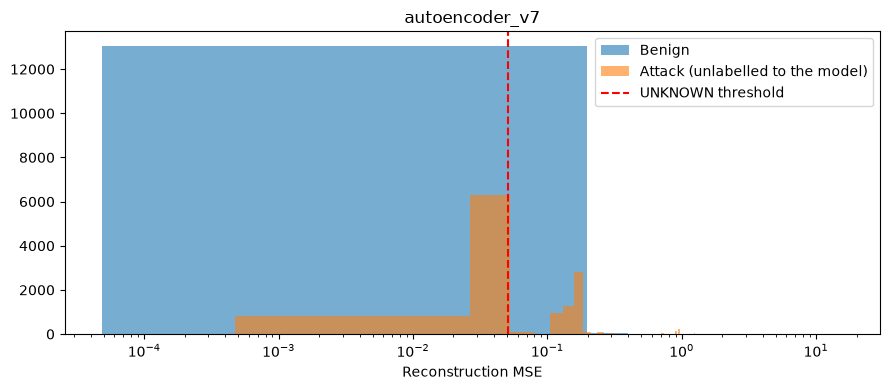

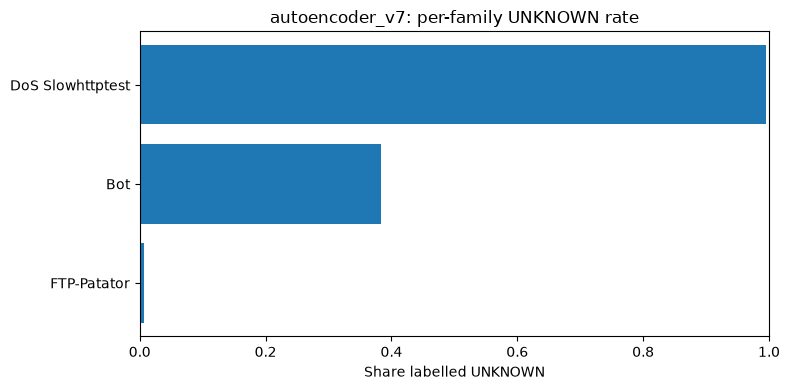

Saved to: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\outputs\results\autoencoder_v7


In [6]:
plt.figure(figsize=(9, 4))
plt.hist(scores[~is_attack], bins=80, alpha=.6, label='Benign')
plt.hist(scores[is_attack], bins=80, alpha=.6, label='Attack (unlabelled to the model)')
plt.axvline(threshold, color='red', linestyle='--', label='UNKNOWN threshold')
plt.xscale('log'); plt.legend(); plt.xlabel('Reconstruction MSE'); plt.title(f'autoencoder_{VERSION}'); plt.tight_layout()
plt.savefig(RESULTS_DIR / f'autoencoder_{VERSION}_score_distribution.png', dpi=150); plt.show()
fam_plot = family.sort_values('UNKNOWN_rate')
plt.figure(figsize=(8, 4)); plt.barh(fam_plot.index, fam_plot['UNKNOWN_rate']); plt.xlim(0, 1)
plt.xlabel('Share labelled UNKNOWN'); plt.title(f'autoencoder_{VERSION}: per-family UNKNOWN rate'); plt.tight_layout()
plt.savefig(RESULTS_DIR / f'autoencoder_{VERSION}_family_unknown_rate.png', dpi=150); plt.show()
print('Saved to:', RESULTS_DIR.resolve())

In [7]:
# Per-attack UNKNOWN detection analysis

# Use the same anomaly scores and threshold
# that your V7 notebook uses for final predictions.

predicted_unknown = scores > threshold

results = pd.DataFrame({
    "Attack_Type": test_df["Label"].astype(str).str.strip().values,
    "Actual_Attack": is_attack,
    "Reconstruction_Error": scores,
    "Predicted_Unknown": predicted_unknown
})

attack_results = results[
    results["Actual_Attack"]
].copy()

per_attack = (
    attack_results
    .groupby("Attack_Type")
    .agg(
        Total_Samples=("Predicted_Unknown", "size"),
        Detected=("Predicted_Unknown", "sum"),
        Mean_Error=("Reconstruction_Error", "mean"),
        Median_Error=("Reconstruction_Error", "median")
    )
)

per_attack["Missed"] = (
    per_attack["Total_Samples"] - per_attack["Detected"]
)

per_attack["Detection_Rate_%"] = (
    per_attack["Detected"] /
    per_attack["Total_Samples"] * 100
)

display(
    per_attack.sort_values("Detection_Rate_%")
)

,Total_Samples,Detected,Mean_Error,Median_Error,Missed,Detection_Rate_%
Attack_Type,,,,,,
FTP-Patator,5931,42,0.038910,0.040113,5889,0.708144
Bot,1948,746,0.077916,0.037055,1202,38.295688
DoS Slowhttptest,5228,5199,0.244610,0.168697,29,99.445295


In [8]:
benign_errors = results.loc[
    ~results["Actual_Attack"],
    "Reconstruction_Error"
].to_numpy()

attack_errors = results.loc[
    results["Actual_Attack"],
    "Reconstruction_Error"
].to_numpy()

percentiles = [10, 25, 50, 75, 90, 95, 99]

comparison = pd.DataFrame({
    "Percentile": percentiles,
    "BENIGN_Error": np.percentile(
        benign_errors, percentiles
    ),
    "UNKNOWN_Error": np.percentile(
        attack_errors, percentiles
    )
})

print("Frozen anomaly threshold:", threshold)

display(comparison)

Frozen anomaly threshold: 0.05095853030681598


,Percentile,BENIGN_Error,UNKNOWN_Error
0,10,0.000176,0.032216
1,25,0.000426,0.039297
2,50,0.002422,0.044603
3,75,0.008313,0.168688
4,90,0.021889,0.168721
5,95,0.037292,0.285611
6,99,0.104534,0.965533


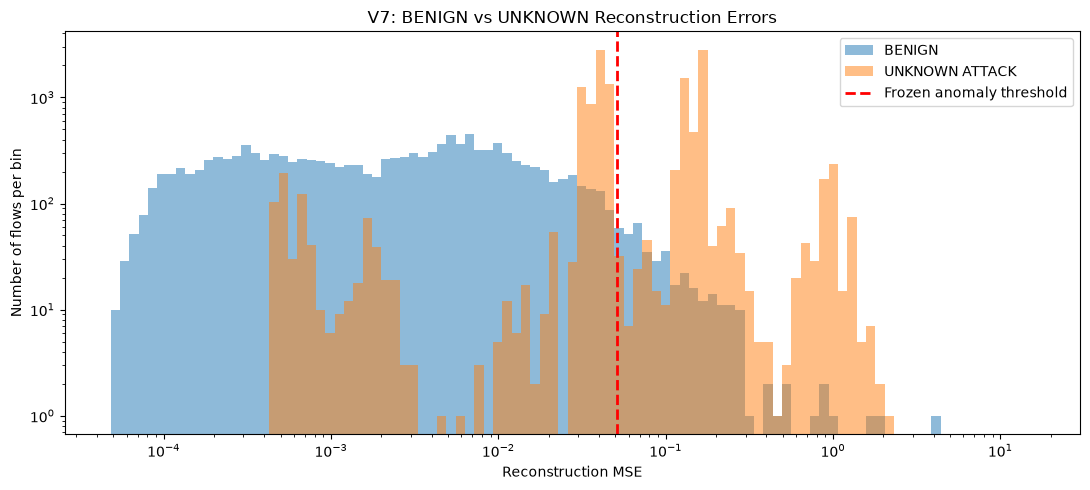

In [9]:
all_errors = np.concatenate([
    benign_errors,
    attack_errors
])

positive_errors = all_errors[all_errors > 0]

if len(positive_errors) == 0:
    raise ValueError("No positive reconstruction errors found.")

bins = np.logspace(
    np.log10(positive_errors.min()),
    np.log10(positive_errors.max()),
    100
)

plt.figure(figsize=(11, 5))

plt.hist(
    benign_errors,
    bins=bins,
    alpha=0.5,
    label="BENIGN"
)

plt.hist(
    attack_errors,
    bins=bins,
    alpha=0.5,
    label="UNKNOWN ATTACK"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Frozen anomaly threshold"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Reconstruction MSE")
plt.ylabel("Number of flows per bin")
plt.title("V7: BENIGN vs UNKNOWN Reconstruction Errors")

plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# Compare feature reconstruction errors
# for missed and detected unknown attacks.

reconstructions = np.mean(
    [
        model.predict(
            X_scaled,
            batch_size=4096,
            verbose=0
        )
        for model in models
    ],
    axis=0
)

feature_errors = np.square(
    X_scaled - reconstructions
)

missed = is_attack & (scores <= threshold)
detected = is_attack & (scores > threshold)

print("Missed attacks:", missed.sum())
print("Detected attacks:", detected.sum())

feature_comparison = pd.DataFrame({
    "Feature_Index": np.arange(X_scaled.shape[1]),
    "Missed_Attack_MSE": feature_errors[missed].mean(axis=0),
    "Detected_Attack_MSE": feature_errors[detected].mean(axis=0)
})

feature_comparison["Difference"] = (
    feature_comparison["Detected_Attack_MSE"]
    - feature_comparison["Missed_Attack_MSE"]
)

display(
    feature_comparison.sort_values(
        "Difference",
        ascending=False
    ).head(20)
)

Missed attacks: 7120
Detected attacks: 5987


,Feature_Index,Missed_Attack_MSE,Detected_Attack_MSE,Difference
62,62,0.009474,1.308525,1.299052
66,66,0.008538,0.879137,0.870598
13,13,0.038433,0.593652,0.555219
5,5,0.049053,0.444363,0.395311
56,56,0.047479,0.440952,0.393473
19,19,0.024374,0.400334,0.375960
64,64,0.002788,0.347901,0.345113
27,27,0.021143,0.353041,0.331898
46,46,0.008665,0.323441,0.314776
70,70,0.011494,0.325546,0.314052


In [ ]:
labels = test_df["Label"].astype(str).str.strip()

# Existing V7 scores and frozen threshold
missed_mask = is_attack & (scores <= threshold)
detected_mask = is_attack & (scores > threshold)
benign_mask = ~is_attack

print("Missed attacks:", missed_mask.sum())
print("Detected attacks:", detected_mask.sum())

for attack in ["Bot", "FTP-Patator", "DoS Slowhttptest"]:
    mask = labels.eq(attack).to_numpy()

    print(
        attack,
        "| Total:", mask.sum(),
        "| Missed:", (mask & missed_mask).sum(),
        "| Detected:", (mask & detected_mask).sum()
    )

In [1]:
features_to_check = [
    "Destination Port",
    "Packet Length Mean",
    "Average Packet Size",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow IAT Mean"
]

groups = {
    "BENIGN": benign_mask,
    "Missed Bot": labels.eq("Bot").to_numpy() & missed_mask,
    "Missed FTP": labels.eq("FTP-Patator").to_numpy() & missed_mask
}

rows = []

for feature in features_to_check:
    for group_name, mask in groups.items():
        values = test_df.loc[mask, feature].to_numpy()

        if len(values) == 0:
            continue

        rows.append({
            "Feature": feature,
            "Group": group_name,
            "Samples": len(values),
            "Median": np.median(values),
            "P25": np.percentile(values, 25),
            "P75": np.percentile(values, 75)
        })

comparison = pd.DataFrame(rows)

display(comparison)

NameError: name 'benign_mask' is not defined

In [ ]:
# Use the saved V7 preprocessing
X_scaled = transform(X_test, prep)

# Get reconstruction from each ensemble model
reconstructions = [
    model.predict(
        X_scaled,
        batch_size=4096,
        verbose=0
    )
    for model in models
]

# Average squared errors across the ensemble
feature_errors = np.mean(
    [
        np.square(X_scaled - reconstruction)
        for reconstruction in reconstructions
    ],
    axis=0
)

transformed_features = (
    ["Port Rarity"]
    + [f for f in FEATURES if f != "Destination Port"]
    + [
        "Port < 1024",
        "Port 1024-49151",
        "Port >= 49152"
    ]
)

assert len(transformed_features) == feature_errors.shape[1]

In [ ]:
# Focus on the features identified in your earlier analysis
important_features = [
    "Packet Length Mean",
    "Average Packet Size",
    "Flow Duration",
    "Flow IAT Mean",
    "Port Rarity"
]

display(
    error_table.loc[
        error_table.index.intersection(important_features)
    ]
)